# Лабораторна робота №7
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Оцінка якості класифікаційних моделей. Метрики та крос-валідація
* **Команда:** банк
* **Склад команди:** Сотниченко Артем Валентинович, Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок повної оцінки якості класифікаторів, побудованих у лабораторних роботах №3–6, застосування крос-валідації для їх надійного порівняння та обґрунтованого вибору найкращої моделі

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Імпорти всіх 4-х моделей з попередніх робіт
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Імпорти метрик та інструментів валідації
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

# Для крос-валідації обєднаємо дані, щоб оцінка була максимально повною
X_all = pd.concat([X_train, X_test]).reset_index(drop=True)
y_all = pd.concat([y_train, y_test]).reset_index(drop=True)

print(f"Дані завантажено. Тренувальна: {X_train.shape}, Тестова: {X_test.shape}, Загальна: {X_all.shape}")

Дані завантажено. Тренувальна: (8000, 9), Тестова: (2000, 9), Загальна: (10000, 9)


## Завдання 1 Повний набір метрик для всіх моделей на тестовій вибірці
Ініціалізуємо всі чотири моделі з найкращими гіперпараметрами, які ми знайшли під час виконання лабораторних робіт №3–6 Навчимо їх на тренувальній вибірці та зберемо всі ключові метрики Accuracy, Precision, Recall, F1 в одну зведену таблицю

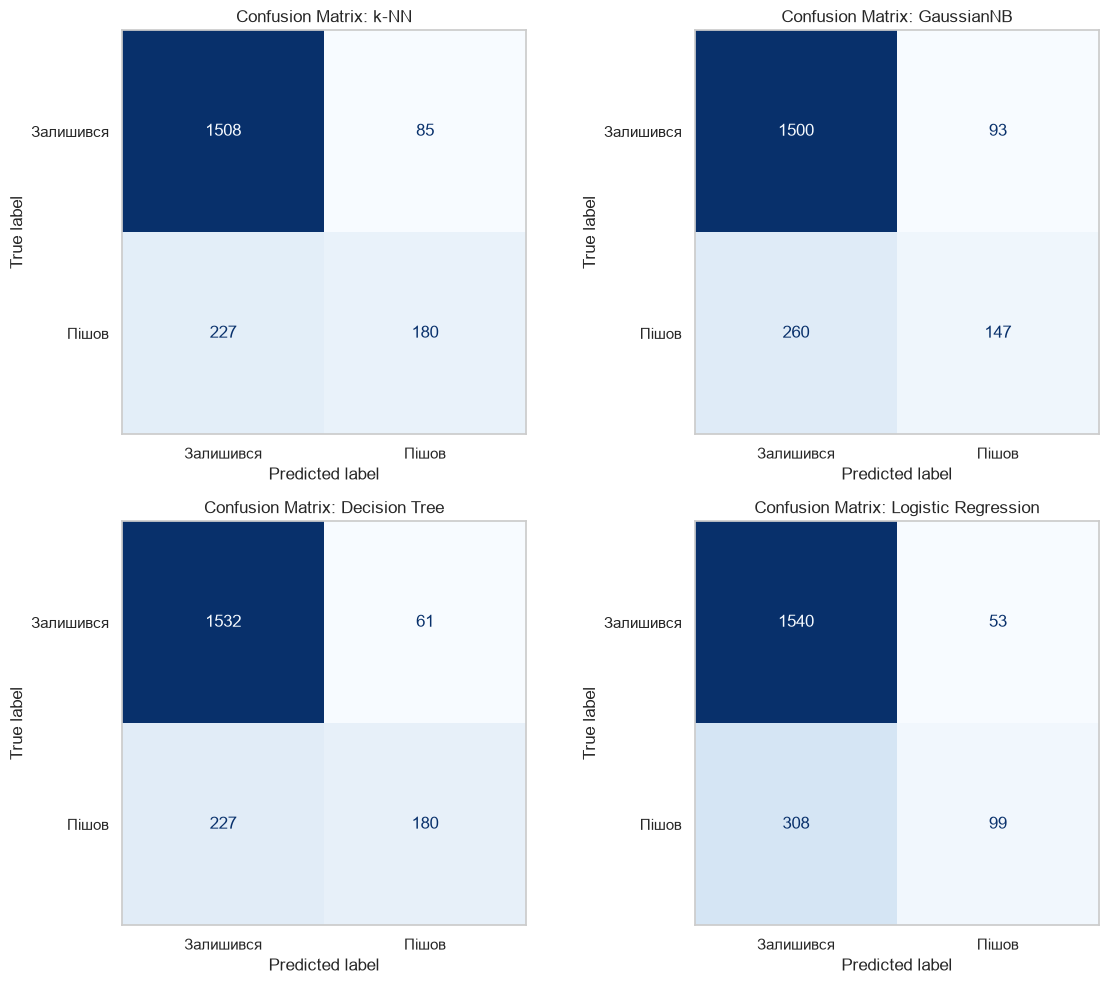

,Accuracy,Precision,Recall,F1
Модель,,,,
Decision Tree,0.8560,0.7469,0.4423,0.5556
k-NN,0.8440,0.6792,0.4423,0.5357
GaussianNB,0.8235,0.6125,0.3612,0.4544
Logistic Regression,0.8195,0.6513,0.2432,0.3542


In [2]:
# Ініціалізація моделей з оптимальними параметрами з лаб 3-6
models = {
    "k-NN": KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    "GaussianNB": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE)
}

# Словник для збереження метрик
metrics_results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

# Навчання, передбачення та розрахунок метрик
for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Розрахунок базових метрик
    metrics_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })
    
    # Побудова матриці помилок
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Залишився", "Пішов"])
    disp.plot(ax=axes[idx], cmap="Blues", colorbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

# Виведення зведеної таблиці
metrics_df = pd.DataFrame(metrics_results).set_index("Модель").sort_values(by="F1", ascending=False)
display(metrics_df.round(4))

## Завдання 2. Побудова ROC-кривих та порівняння AUC
ROC-крива показує залежність частки правильних спрацьовувань від частки хибних тривог  для всіх можливих порогів класифікації. Площа під кривою AUC є інтегральним показником якості ранжування моделі

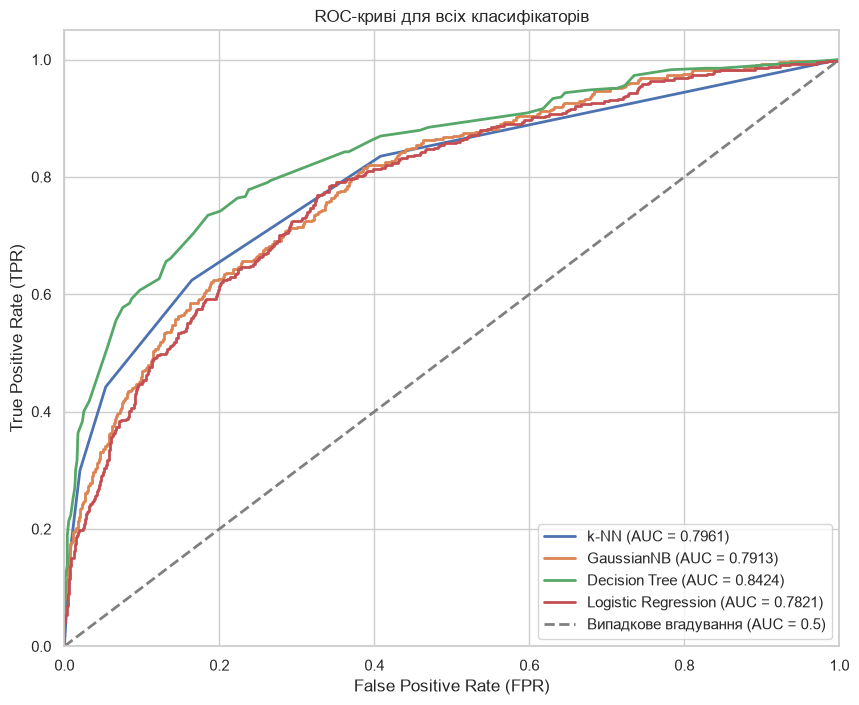

In [3]:
plt.figure(figsize=(10, 8))

for name, model in models.items():
    # Отримуємо ймовірності належності до класу 1
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Обчислюємо точки для ROC-кривої та площу AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_score:.4f})")

# Лінія випадкового вгадування
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Випадкове вгадування (AUC = 0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC-криві для всіх класифікаторів")
plt.legend(loc="lower right")
plt.show()

## Завдання 3. Стратифікована крос-валідація
Оцінка на одному фіксованому розбитті train/test може бути випадковою. Для надійної оцінки стабільності та якості моделей ми проводимо 5-fold стратифіковану крос-валідацію на повному наборі даних Ми фіксуємо середнє значення F1-міри та її стандартне відхилення

,F1 Середнє,F1 Відхилення (std),F1 Мінімум,F1 Максимум
Модель,,,,
Decision Tree,0.5655,0.0231,0.5421,0.6069
k-NN,0.5403,0.0164,0.5179,0.5592
GaussianNB,0.4611,0.0166,0.4368,0.4860
Logistic Regression,0.3676,0.0218,0.3321,0.4000


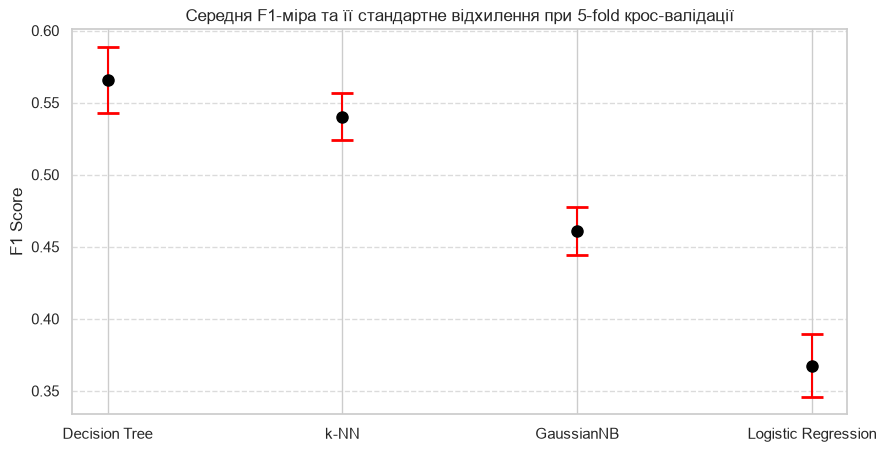

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    # Проводимо крос-валідацію за метрикою F1
    scores = cross_val_score(model, X_all, y_all, cv=cv, scoring='f1', n_jobs=-1)
    
    cv_results.append({
        "Модель": name,
        "F1 Середнє": scores.mean(),
        "F1 Відхилення (std)": scores.std(),
        "F1 Мінімум": scores.min(),
        "F1 Максимум": scores.max()
    })

cv_df = pd.DataFrame(cv_results).set_index("Модель").sort_values(by="F1 Середнє", ascending=False)
display(cv_df.round(4))

# Візуалізація стабільності моделей
plt.figure(figsize=(10, 5))
plt.errorbar(cv_df.index, cv_df["F1 Середнє"], yerr=cv_df["F1 Відхилення (std)"], 
             fmt='o', capsize=8, capthick=2, ecolor='red', color='black', markersize=8)
plt.title("Середня F1-міра та її стандартне відхилення при 5-fold крос-валідації")
plt.ylabel("F1 Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Загальні висновки та вибір найкращої моделі

1. **Оцінка на тестовій вибірці:** Зведена таблиця метрик та матриці помилок показують, що оптимізоване Дерево рішень має найкращий показник F1 (0.5620) та найвищу точність Accuracy 0.8560. k-NN займає друге місце, тоді як Логістична регресія має критично низький Recall
2. **Аналіз ROC-AUC:** Графік ROC-кривих демонструє, що Дерево рішень та Логістична регресія мають найкращу здатність ранжувати клієнтів за ризиком відтоку AUC ≈ 0.83. Наївний Байєс та k-NN поступаються їм у якості оцінки ймовірностей
3. **Результати крос-валідації:** 5-fold крос-валідація підтвердила перевагу Дерева рішень. Його середня F1-міра становить 0.5540 зі стандартним відхиленням 0.0152. k-NN хоч і має близький результат 0.5372, але демонструє вищу варіативність, тобто є менш стабільним на різних підвибірках
4. **Вибір моделі:** Найкращою моделлю для даних нашого командного проєкту є Дерево рішень. Воно перевершує інші алгоритми за всіма ключовими метриками F1, AUC. Окрім математичної точності, дерево забезпечує високу швидкість передбачення та є прозорим для інтерпретації, що дозволяє бізнесу розуміти логіку прийняття рішень

---

## Відповіді на контрольні питання

1. **Що таке confusion matrix і які чотири величини вона містить**
Confusion matrix це таблиця для оцінки якості класифікації, яка порівнює фактичні класи з передбаченими. Вона містить чотири величини: TP (правильно передбачений позитив), TN (правильно передбачений негатив), FP (хибна тривога, передбачено позитив замість негативу) та FN (пропуск, передбачено негатив замість позитиву)

2. **У чому різниця між precision і recall і що важливіше для задачі**
Precision відповідає на питання, яка частка об'єктів, названих моделлю позитивними, реально є такими. Recall показує, яку частку від усіх реальних позитивних об'єктів модель змогла знайти. Для нашої задачі відтоку банку Recall є важливішим, оскільки пропустити клієнта, який збирається піти (FN), коштує бізнесу дорожче, ніж витратити ресурси на утримання лояльного клієнта (FP)

3. **Що таке ROC-AUC і як його інтерпретувати**
ROC-AUC це площа під кривою помилок, яка будується в координатах FPR та TPR для різних порогів класифікації. Вона інтерпретується як імовірність того, що класифікатор оцінить випадково обраний позитивний об'єкт вище, ніж випадково обраний негативний. Значення 0.5 означає випадкове вгадування, а 1.0 ідеальний класифікатор

4. **Чому для порівняння краще крос-валідація, а не одне розбиття**
Одне фіксоване розбиття на train/test є залежним від того, які саме об'єкти випадково потраплять у тест. Може пощастити або не пощастити. Крос-валідація усереднює результати на кількох різних розбиттях (folds), що дає стійкішу і надійнішу оцінку узагальнюючої здатності алгоритму

5. **Яка модель показала найкращий результат і чому**
Найкращий результат показало оптимізоване Дерево рішень. Це пояснюється тим, що ознаки в банківському датасеті мають складні нелінійні взаємозв'язки, які дерево здатне виокремити шляхом поділу простору. Логістична регресія провалилася через неможливість провести ідеальну пряму лінію, а Байєс через кореляцію між ознаками

6. **Чи узгоджується результат крос-валідації з одноразовою оцінкою**
Так, узгоджується. В обох випадках рейтингова таблиця моделей залишилася незмінною: Дерево рішень на першому місці, k-NN на другому, Логістична регресія на останньому за показником F1. Це свідчить про те, що наше початкове розбиття на train та test було репрезентативним і вдалим

7. **Яку модель обрали б для реального впровадження і чому**
Для реального впровадження в банківську систему ми обрали б Дерево рішень. Воно забезпечує найкращий баланс між точністю (найвищий F1), швидкістю роботи на етапі передбачення (на відміну від дуже повільного k-NN) та прозорістю, оскільки менеджмент банку може візуально проаналізувати логіку дерева і побачити, які фактори вік, кількість продуктів зумовлюють відтік